In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [3]:
wt_pca= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/wt/rep{rep}/analysis/003_pca/2dproj_timescale.csv', header=None)
    wt_pca.append(df)

T419R_pca= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/T419R/rep{rep}/analysis/003_pca/2dproj_timescale.csv', header=None)
    T419R_pca.append(df)

S466R_pca= []
for rep in range(1, 4):
    df = pd.read_csv(f'../../data/1bf5/S466R/rep{rep}/analysis/003_pca/2dproj_timescale.csv', header=None)
    S466R_pca.append(df)

In [4]:
wt_pca[1].columns

Index([0, 1, 2], dtype='int64')

In [5]:
all_pca = wt_pca + T419R_pca + S466R_pca
y_min = min(df[1].min() for df in all_pca)
y_max = max(df[1].max() for df in all_pca)

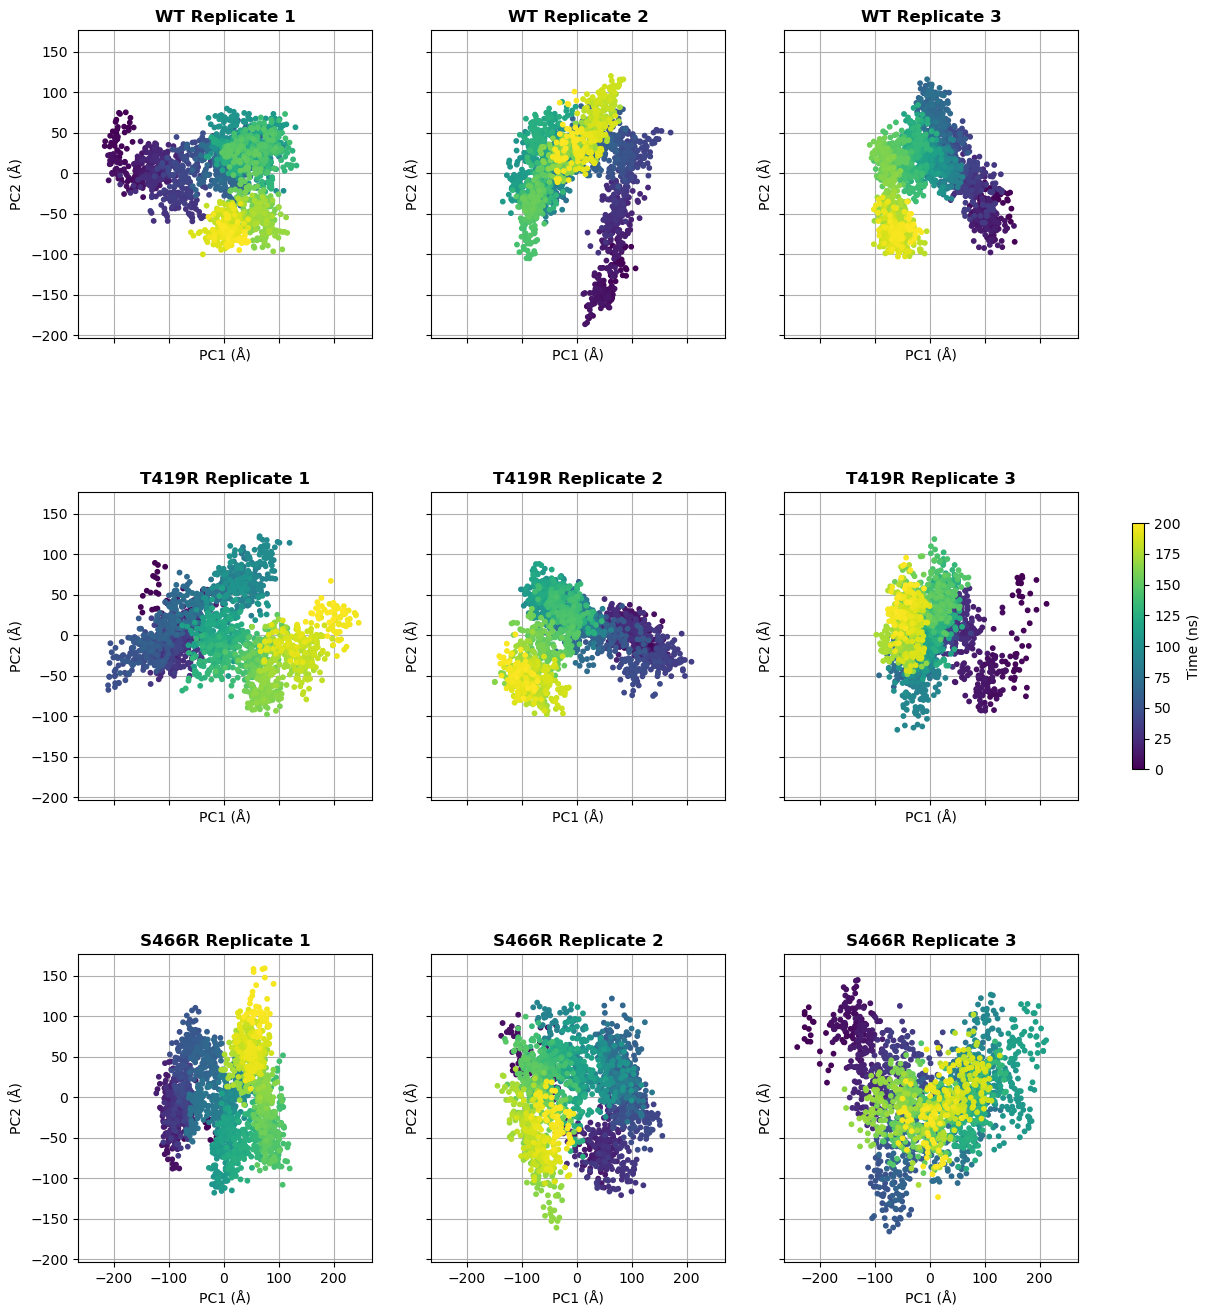

In [27]:
fig, axes = plt.subplots(3, 3, figsize=(16, 16), sharex=True, sharey=True)

# Plot WT replicates
for i, (df, ax) in enumerate(zip(wt_pca, axes[0, :])):
    scatter = ax.scatter(df[0], df[1], c=df[2], cmap='viridis', s=10)
    ax.set_title(f'WT Replicate {i+1}', fontweight='bold')
    ax.set_xlabel('PC1 (Å)')
    ax.set_ylabel('PC2 (Å)')
    ax.set_axisbelow(True)
    ax.grid(True)

# Plot T419R replicates
for i, (df, ax) in enumerate(zip(T419R_pca, axes[1, :])):
    scatter = ax.scatter(df[0], df[1], c=df[2], cmap='viridis', s=10)
    ax.set_title(f'T419R Replicate {i+1}', fontweight='bold')
    ax.set_xlabel('PC1 (Å)')
    ax.set_ylabel('PC2 (Å)')
    ax.set_axisbelow(True)
    ax.grid(True)

# Plot S466R replicates
for i, (df, ax) in enumerate(zip(S466R_pca, axes[2, :])):
    scatter = ax.scatter(df[0], df[1], c=df[2], cmap='viridis', s=10)
    ax.set_title(f'S466R Replicate {i+1}', fontweight='bold')
    ax.set_xlabel('PC1 (Å)')
    ax.set_ylabel('PC2 (Å)')
    ax.set_axisbelow(True)
    ax.grid(True)

# Adjust layout and add shared colorbar to the right
cbar = fig.colorbar(scatter, ax=axes, location='right', shrink=0.2, label='Time (ns)')


plt.subplots_adjust(hspace=0.5, right=0.75)
plt.show()


Silhouette score comparison

In [7]:
wt_hclust = [0.48, 0.55, 0.53]
wt_kmeans = [0.45, 0.55, 0.48]

T419R_hclust = [0.53, 0.55, 0.46]
T419R_kmeans = [0.53, 0.54, 0.45]

S466R_hclust = [0.51, 0.56, 0.45]
S466R_kmeans = [0.49, 0.56, 0.43]

# Mean and std
print("WT Hierarchical clustering:")
print("Mean =", np.mean(wt_hclust ))
print("Std  =", np.std(wt_hclust ))
print("\n WT K-means clustering:")
print("Mean =", np.mean(wt_kmeans))
print("Std  =", np.std(wt_kmeans))

print("\nT419R Hierarchical clustering:")
print("Mean =", np.mean(T419R_hclust))
print("Std  =", np.std(T419R_hclust))
print("\nT419R K-means clustering:")
print("Mean =", np.mean(T419R_kmeans))
print("Std  =", np.std(T419R_kmeans))

print("\nS466R Hierarchical clustering:")
print("Mean =", np.mean(S466R_hclust))
print("Std  =", np.std(S466R_hclust))
print("\nS466R K-means clustering:")
print("Mean =", np.mean(S466R_kmeans))
print("Std  =", np.std(S466R_kmeans))

print("\nCombined Hierarchical clustering:")
print("Mean =", np.mean([*S466R_hclust, *T419R_hclust, *wt_hclust]))
print("Std  =", np.std([*S466R_hclust, *T419R_hclust, *wt_hclust]))
print("\nCombined K-means clustering:")
print("Mean =", np.mean([*S466R_kmeans, *T419R_kmeans, *wt_kmeans]))
print("Std  =", np.std([*S466R_kmeans, *T419R_kmeans, *wt_kmeans]))


WT Hierarchical clustering:
Mean = 0.52
Std  = 0.029439202887759516

 WT K-means clustering:
Mean = 0.49333333333333335
Std  = 0.0418993502999218

T419R Hierarchical clustering:
Mean = 0.5133333333333333
Std  = 0.03858612300930076

T419R K-means clustering:
Mean = 0.5066666666666667
Std  = 0.04027681991198191

S466R Hierarchical clustering:
Mean = 0.5066666666666667
Std  = 0.04496912521077349

S466R K-means clustering:
Mean = 0.49333333333333335
Std  = 0.053124591501697446

Combined Hierarchical clustering:
Mean = 0.5133333333333333
Std  = 0.03858612300930077

Combined K-means clustering:
Mean = 0.4977777777777778
Std  = 0.04589305872902976
